Preparação OpenDSS

In [ ]:
import pandas as pd
from pathlib import Path
import os
import py_dss_interface
from py_dss_toolkit import dss_tools

caminho = Path(os.getcwd())

dss_file = caminho / "Master_PyDSS_Interface.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

dss.text(f"compile [{dss_file}]")
dss.text("buscoords buscoords.csv")

def decide_element(bus: str, buses_df: pd.DataFrame, trafo_df: pd.DataFrame, lines_df: pd.DataFrame):
    bus = bus.split(".")[0]
    elements_query = buses_df.query(f"name == '{bus}'")["all_pde_active_bus"].iloc[0]

    distance = 1e6
    for element in elements_query:
        element_type, element_name = element.split(".")

        if element_type == "Line":
            segment_df = lines_df.query(f"name == '{element_name}'")

            element_bus = segment_df["bus_name"].iloc[0]
            distance_bus = buses_df.query(f"name == '{element_bus}'")["distance"].iloc[0]

            if "mt" in element_name:
                kv = 13.8

            elif "bt" in element_name:
                kv = 0.38

            else:
                continue

        elif element_type == "Transformer":
            element_bus = trafo_df.query(f"name == '{element_name}'")["bus_name"].iloc[0]
            distance_bus = buses_df.query(f"name == '{element_bus}'")["distance"].iloc[0]
            kv = trafo_df.query(f"name == '{element_name}'")["kv"].iloc[0]

        else:
            continue

        if distance_bus < distance:
            distance = distance_bus
            selected_element = element_name
            selected_element_type = element_type
            selected_kv = kv

    return selected_element_type, selected_element, selected_kv

def calc_rpf() -> float:
    soma = 0
    for name in dss.monitors.names:
        if "voltage" in name:
            continue

        if "battery" in name:
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        soma += sum(x for x in monitor if x < 0)

    return soma

def calc_separated_rpf() -> tuple[float, float]:
    soma = 0
    soma_feeder = 0
    for name in dss.monitors.names:
        if "voltage" in name:
            continue

        if "battery" in name:
            continue

        dss.monitors.name = name
        monitor = dss.monitors.channel(1)

        if "feeder" in name:  
            soma_feeder += sum(x for x in monitor if x < 0)
            continue

        soma += sum(x for x in monitor if x < 0)

    return soma, soma_feeder

buses_df = dss_tools.model.buses_df
trafo_df = dss_tools.model.transformers_df
lines_df = dss_tools.model.lines_df
loads_df = dss_tools.model.loads_df

loads_df["kw"] = pd.to_numeric(loads_df["kw"], errors="coerce")
loads_df["kv"] = pd.to_numeric(loads_df["kv"], errors="coerce")

trafo_df["bus_name"] = trafo_df["bus"].str.split(".").str[0]
lines_df["bus_name"] = lines_df["bus1"].str.split(".").str[0]


buses_df = buses_df[["name", "distance", "x", "y", "all_pce_active_bus", "all_pde_active_bus"]]


Análise Fluxo de Potência


Caso Base


,kwh,kvarh,zone kwh,zone losses kwh
0,90481.609609,133033.366286,241381.928286,12238.705488



Convergência das ações de controle:  1
Número de iterações de controle:  3

Caso Ótimo


,kwh,kvarh,zone kwh,zone losses kwh
0,91937.24811,129856.380999,241496.746618,10932.687528


,Caso,Fluxo Reverso Total (kWh),Fluxo Reverso Trafos (kWh),Fluxo Reverso Alimentador,Fitness
0,Caso Base,-51543.961716,-32008.980148,-19534.981567,83552.941864
1,Caso Ótimo,-41100.559357,-30211.265831,-10889.293526,71311.825187


Gráficos


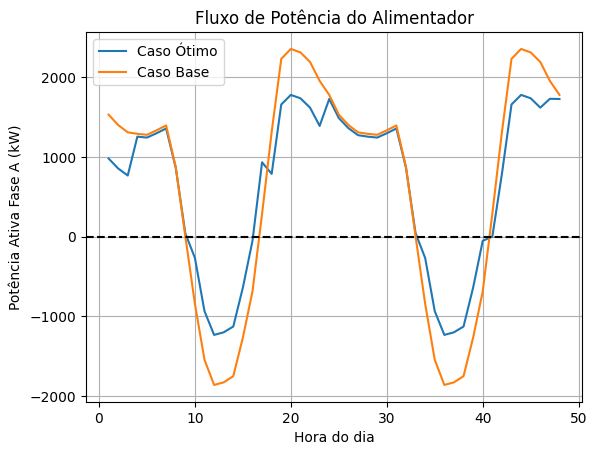

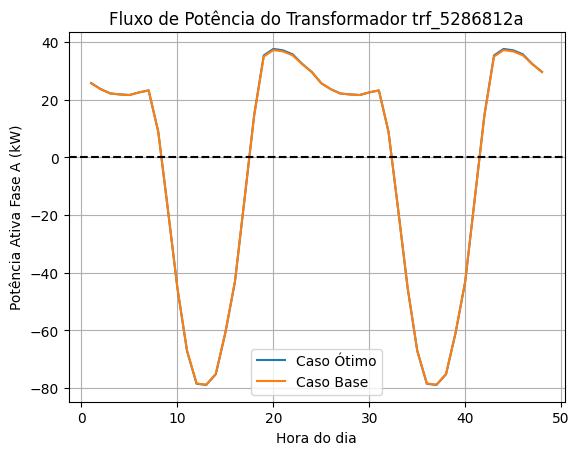

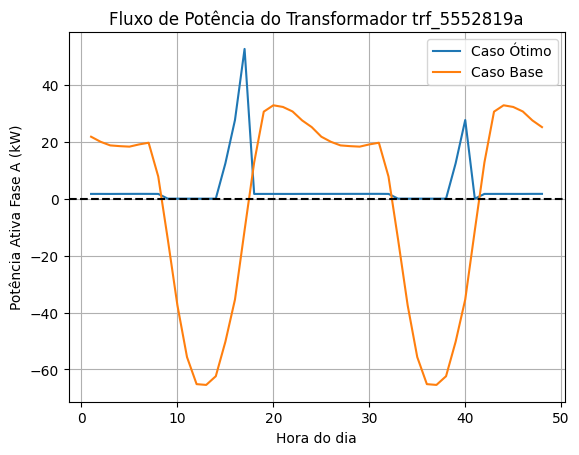

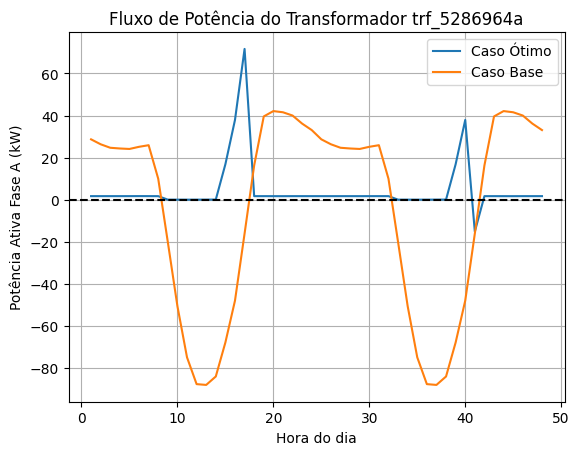

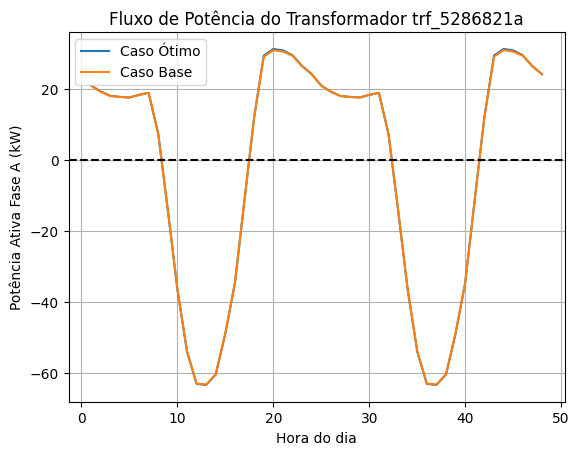

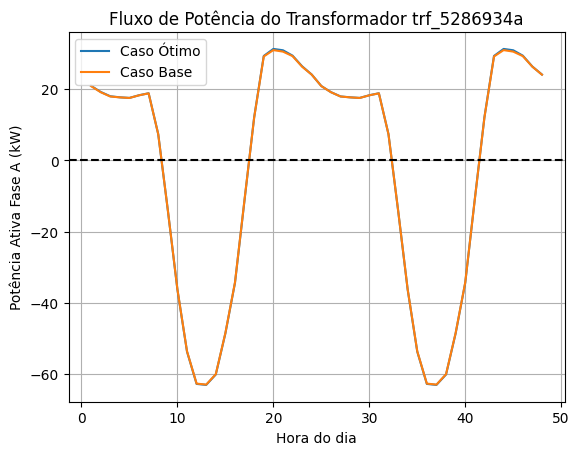

In [ ]:
import py_dss_interface
from py_dss_toolkit import dss_tools
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

cases = ["Caso Base", "Caso Ótimo"]

#solution_buses = ['82034745002086', '81489185002086', '82034755002086', '81460575002086', '82054835002086'] #Solução encontrada 1a tentativa PSO
#solution_buses = ['82042645002086', '82034745002086', '81460535002086', '82034755002086', '82034765002086'] #Solução encontrada 2a tentativa PSO
#solution_buses = ['82034745002086', '81489055002086', '82034755002086', '82034765002086', '82065635002086'] #3a tentativa - 200 gerações
#solution_buses = ['82042645002086', '82034745002086', '82034765002086', '82034755002086', '81489215002086'] #4a tentativa -> 200 gerações e 2 dias 
#solution_buses = ['82034765002086', '81460535002086', '81489115002086', '82062735002086', '82026915286812'] #6a tentativa -> 377 gerações e 1 dia
#solution_buses = ['82026915286812', '94329985002086', '81489115002086', '82021055002086b', '90855665286807'] #7a tentativa 377 gerações e 1 dia
#solution_buses = ['82040725002086', '82033185002086', '82038095286834', '82027915002086', '82031445286959'] #Deu errado
#solution_buses = ['82033655002086', '82042285002086', '91881405002086', '81460585002086', '82032105469845'] #Deu errado
#solution_buses = ['82023305002086', '82034755002086', '82026915286812', '82034385002086', '82036275286964'] #8a tentativa 377 gerações e 2 dias
solution_buses = ['81489215002086', '82034745002086', '82032765552819', '81460505002086', '82036275286964']

#solution_powers = [499.19654479, 499.93742891, 499.5781339, 499.9485783, 498.9629871] #Solução encontrada 1a tentativa PSO
#solution_powers = [498.18804854, 499.88670448, 495.40147567, 498.99292383, 499.05359095] #Solução encontrada 2a tentativa PSO
#solution_powers = [499.9631814749751, 499.9865814230642, 499.99894342851684, 499.98439966247935, 499.99761357032787] #3a tentativa - 200 gerações
#solution_powers = [499.99999999935204, 499.99999999818164, 499.9999999768928, 500.0, 499.99999996521535] #4a tentativa -> 200 gerações e 2 dias
#solution_powers = [499.9554805555674, 499.9998449594651, 497.4879349546035, 499.5872299222844, 285.10192370702686] #6a tentativa -> 377 gerações e 1 dia
#solution_powers = [471.4471019151277, 499.4023601541618, 499.99977503533444, 498.63259718572806, 160.20321666557314] #7a tentativa 377 gerações e 1 dia 
#solution_powers = [302.0281455799066, 499.9938320512961, 499.9470918425051, 482.8495190998335, 377.933487126925]
#solution_powers = [499.4715413004145, 497.449884688993, 431.8822269034508, 499.9973659747075, 276.38091271539105] #8a tentativa 377 gerações e 2 dias
solution_powers = [497.53301106069, 497.3347303069823, 424.0067977480447, 499.9996909031204, 276.2972692874432]

powers = solution_powers

caminho = Path(os.getcwd())

dss_file = caminho / "Master_PyDSS_Interface.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

df_rpf = pd.DataFrame(columns=["Caso", "Fluxo Reverso Total (kWh)"])

voltage_dfs_base_case = {}

for case in cases:

    dss.text(f"compile [{dss_file}]")

    #dss.text("Redirect 'PV_System_120_MeiaPonte.dss'")
    dss.text("Redirect 'PVSystem_120_Irrad.dss")
    #dss.text("buscoords buscoords.csv")

    if case == "Caso Ótimo":

        for i, (power, bus) in enumerate(zip(powers, solution_buses)):
            element_type, element_name, kv = decide_element(bus, buses_df, trafo_df, lines_df)
            pot = power

            dss.text(f"New Storage.Battery_{i} phases=3 bus1={bus} kv={kv} kWrated={pot} kWhrated={8*pot} dispmode=follow %stored=50")
            
            dss.text(f"New StorageController.SC_{i} element={element_type}.{element_name} terminal=1 modedis=peakShave elementList=[Battery_{i}]\n"
            f"~ MonPhase=AVG kwtarget=5 modecharge=peakShaveLow kwtargetLow=0\n\n")

            dss.text(f"New Monitor.Battery_{i} element=Storage.Battery_{i} mode=7")

    dss.text(f"buscoords BusCoords.csv")

    dss.text("set mode=daily")
    dss.text("set stepsize=1h")
    dss.text("set number=48")
    dss.text("set maxcontroliter=200")

    dss.solution.solve()

    energymeter_df = dss_tools.results.energymeters

    if case == "Caso Base":
        for name in dss.monitors.names:
            if not "voltage" in name:
                continue

            voltage_dfs_base_case[name] = dss_tools.results.monitor(name)

    elem_1, elem_2, elem_3, elem_4, elem_5 = "trf_5286812a", "trf_5552819a", "trf_5286964a", "trf_5286821a", "trf_5286934a"

    if case == "Caso Ótimo":
        print("\nConvergência das ações de controle: ", dss.solution.control_actions_done)
        print("Número de iterações de controle: ", dss.solution.control_iterations)

        df_optimal_feeder = dss_tools.results.monitor("feeder")
        df_optimal_trafo_1 = dss_tools.results.monitor(elem_1)
        df_optimal_trafo_2 = dss_tools.results.monitor(elem_2)
        df_optimal_trafo_3 = dss_tools.results.monitor(elem_3)
        df_optimal_trafo_4 = dss_tools.results.monitor(elem_4)
        df_optimal_trafo_5 = dss_tools.results.monitor(elem_5)

    elif case == "Caso Base":
        df_base_feeder = dss_tools.results.monitor("feeder")
        df_base_trafo_1 = dss_tools.results.monitor(elem_1)
        df_base_trafo_2 = dss_tools.results.monitor(elem_2)
        df_base_trafo_3  = dss_tools.results.monitor(elem_3)
        df_base_trafo_4  = dss_tools.results.monitor(elem_4)
        df_base_trafo_5  = dss_tools.results.monitor(elem_5)

    print(f"\n{case}")
    display(energymeter_df[["kwh", "kvarh", "zone kwh", "zone losses kwh"]])

    rpf = calc_rpf()
    rpf_transf, rpf_feeder = calc_separated_rpf()
    fitness = rpf_transf*2 + rpf_feeder  #w1 = 2
    
    df2 = pd.DataFrame(
        {
            "Caso": [case], 
            "Fluxo Reverso Total (kWh)": [rpf], 
            "Fluxo Reverso Trafos (kWh)": [rpf_transf], 
            "Fluxo Reverso Alimentador": [rpf_feeder],
            "Fitness": [abs(fitness)]
        }
    )

    df_rpf = pd.concat([df_rpf, df2], ignore_index=True)

#Fluxo reverso total
display(df_rpf)

#### Gráfico
print("Gráficos")

# Alimentador
plt.plot(df_optimal_feeder["Hour"], df_optimal_feeder[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_feeder["Hour"], df_base_feeder[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title("Fluxo de Potência do Alimentador")
plt.show()

#Trafo 5286812a
plt.plot(df_optimal_trafo_1["Hour"], df_optimal_trafo_1[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_1["Hour"], df_base_trafo_1[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title(f"Fluxo de Potência do Transformador {elem_1}")
plt.show()

#Trafo 5552819a

plt.plot(df_optimal_trafo_2["Hour"], df_optimal_trafo_2[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_2["Hour"], df_base_trafo_2[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.grid(True)
plt.axhline(y=0, linestyle="--", color="black")
plt.title(f"Fluxo de Potência do Transformador {elem_2}")
plt.show()

#Trafo 5286964a

plt.plot(df_optimal_trafo_3["Hour"], df_optimal_trafo_3[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_3["Hour"], df_base_trafo_3[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_3}")
plt.show()

#Trafo 5286821a

plt.plot(df_optimal_trafo_4["Hour"], df_optimal_trafo_4[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_4["Hour"], df_base_trafo_4[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_4}")
plt.show()

#Trafo 5286934a

plt.plot(df_optimal_trafo_5["Hour"], df_optimal_trafo_5[" P1 (kW)"], label="Caso Ótimo")
plt.plot(df_optimal_trafo_5["Hour"], df_base_trafo_5[" P1 (kW)"], label="Caso Base")
plt.xlabel("Hora do dia")
plt.ylabel("Potência Ativa Fase A (kW)")
plt.legend()
plt.axhline(y=0, linestyle="--", color="black")
plt.grid(True)
plt.title(f"Fluxo de Potência do Transformador {elem_5}")
plt.show()

Convergência da Solução (Controle e Fluxo de Potência)

In [ ]:
import py_dss_interface
from py_dss_toolkit import dss_tools
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

cases = ["Caso Base", "Caso Ótimo"]

#solution_buses = ['82034745002086', '81489185002086', '82034755002086', '81460575002086', '82054835002086'] #Solução encontrada 1a tentativa PSO
#solution_buses = ['82042645002086', '82034745002086', '81460535002086', '82034755002086', '82034765002086'] #Solução encontrada 2a tentativa PSO
#solution_buses = ['82034745002086', '81489055002086', '82034755002086', '82034765002086', '82065635002086'] #3a tentativa - 200 gerações
#solution_buses = ['82042645002086', '82034745002086', '82034765002086', '82034755002086', '81489215002086'] #4a tentativa -> 200 gerações e 2 dias 
#solution_buses = ['81489145002086', '82033655002086', '81488725002086', '82036795002086', '82036275286964']
solution_buses = ['82044325557353', '82062465002086', '82040735002086', '82032275002086', '82044385286867']
solution_buses = ['94511165002086b', '82021835002086', '82044315002086', '82040725002086', '82040575286946'] 

#solution_powers = [499.19654479, 499.93742891, 499.5781339, 499.9485783, 498.9629871] #Solução encontrada 1a tentativa PSO
#solution_powers = [498.18804854, 499.88670448, 495.40147567, 498.99292383, 499.05359095] #Solução encontrada 2a tentativa PSO
#solution_powers = [499.9631814749751, 499.9865814230642, 499.99894342851684, 499.98439966247935, 499.99761357032787] #3a tentativa - 200 gerações
#solution_powers = [499.99999999935204, 499.99999999818164, 499.9999999768928, 500.0, 499.99999996521535] #4a tentativa -> 200 gerações e 2 dias
#solution_powers = [499.89340045596316, 499.94069298067086, 499.9995207156918, 498.29324270056054, 426.1481193146279]
solution_powers = [497.6, 497.76, 461.48, 465.89, 316.22]
solution_powers = [499.9939505589744, 499.518667175502, 499.8356680737645, 196.0026357170039, 266.5817453404978]

powers = solution_powers

caminho = Path(os.getcwd())

dss_file = caminho / "Master_PyDSS_Interface.dss"

dss = py_dss_interface.DSS()

dss_tools.update_dss(dss)

df_rpf = pd.DataFrame(columns=["Caso", "Fluxo Reverso Total (kWh)"])

voltage_dfs_base_case = {}
df_falhas = pd.DataFrame()

for case in cases:

    dss.text(f"compile [{dss_file}]")

    #dss.text("Redirect 'PV_System_120_MeiaPonte.dss'")
    dss.text("Redirect 'PVSystem_120_Irrad.dss")
    #dss.text("buscoords buscoords.csv")

    if case == "Caso Ótimo":

        for i, (power, bus) in enumerate(zip(powers, solution_buses)):
            element_type, element_name, kv = decide_element(bus, buses_df, trafo_df, lines_df)
            pot = power

            dss.text(f"New Storage.Battery_{i} phases=3 bus1={bus} kv={kv} kWrated={pot} kWhrated={8*pot} dispmode=follow %stored=50")
            
            dss.text(f"New StorageController.SC_{i} element={element_type}.{element_name} terminal=1 modedis=peakShave elementList=[Battery_{i}]\n"
            f"~ MonPhase=AVG kwtarget=5 modecharge=peakShaveLow kwtargetLow=0\n\n")

            dss.text(f"New Monitor.Battery_{i} element=Storage.Battery_{i} mode=7")

    dss.text(f"buscoords BusCoords.csv")

    dss.text("set mode=daily")
    dss.text("set stepsize=1h")
    dss.text("set number=1")
    dss.text("set maxcontroliter=200")

    conv_list = []
    ctrl_iter = []
    
    print(f"Falhas de convergência no {case}")
    for h in range(48):
        dss.solution.solve()

        if not dss.solution.converged:
            print(f"Não convergiu na hora {h}")

        if dss.solution.control_iterations >= dss.solution.max_control_iterations:
            print(f"Alcançou o máximo de iterações de controle na hora {h}")

        conv_list.append(dss.solution.converged)
        ctrl_iter.append(dss.solution.control_iterations)

    df_falhas[f"Convergência - {case}"] = conv_list
    df_falhas[f"Iterações de Controle - {case}"] = ctrl_iter

    energymeter_df = dss_tools.results.energymeters

    print(f"\n{case}")
    display(energymeter_df[["kwh", "kvarh", "zone kwh", "zone losses kwh"]])

    rpf = calc_rpf()
    rpf_transf, rpf_feeder = calc_separated_rpf()
    fitness = rpf_transf*2 + rpf_feeder  #w1 = 2
    
    df2 = pd.DataFrame(
        {
            "Caso": [case], 
            "Fluxo Reverso Total (kWh)": [rpf], 
            "Fluxo Reverso Trafos (kWh)": [rpf_transf], 
            "Fluxo Reverso Alimentador": [rpf_feeder],
            "Fitness": [abs(fitness)]
        }
    )

    df_rpf = pd.concat([df_rpf, df2], ignore_index=True)

#Fluxo reverso total
display(df_rpf)
display(df_falhas.head())
display(df_falhas["Convergência - Caso Ótimo"].value_counts().reset_index())
display(df_falhas["Iterações de Controle - Caso Ótimo"].value_counts().reset_index())
display(df_falhas[df_falhas["Iterações de Controle - Caso Ótimo"] > 200])

Falhas de convergência no Caso Base

Caso Base


,kwh,kvarh,zone kwh,zone losses kwh
0,90481.609609,133033.366286,241381.928286,12238.705488


Falhas de convergência no Caso Ótimo

Caso Ótimo


,kwh,kvarh,zone kwh,zone losses kwh
0,217982.509648,106198.083819,239639.820862,9671.361596


,Caso,Fluxo Reverso Total (kWh),Fluxo Reverso Trafos (kWh),Fluxo Reverso Alimentador,Fitness
0,Caso Base,-51543.961716,-32008.980148,-19534.981567,83552.941864
1,Caso Ótimo,0,0.000000,0.000000,0.000000


,Convergência - Caso Base,Iterações de Controle - Caso Base,Convergência - Caso Ótimo,Iterações de Controle - Caso Ótimo
0,1,1,1,51
1,1,1,1,1
2,1,1,1,1
3,1,1,1,1
4,1,1,1,1


,Convergência - Caso Ótimo,count
0,1,48


,Iterações de Controle - Caso Ótimo,count
0,1,47
1,51,1


,Convergência - Caso Base,Iterações de Controle - Caso Base,Convergência - Caso Ótimo,Iterações de Controle - Caso Ótimo


Análise da Convergência do Algoritmo

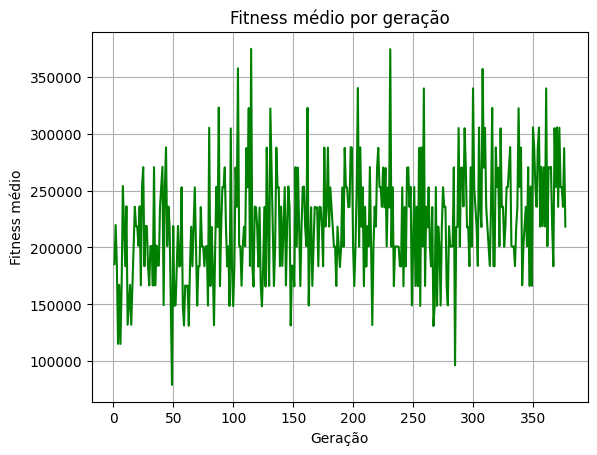

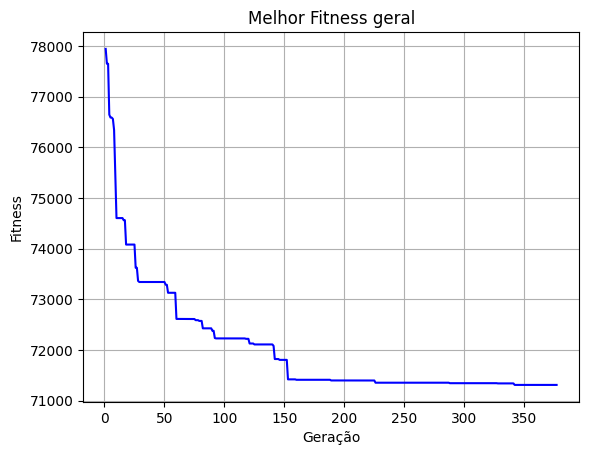

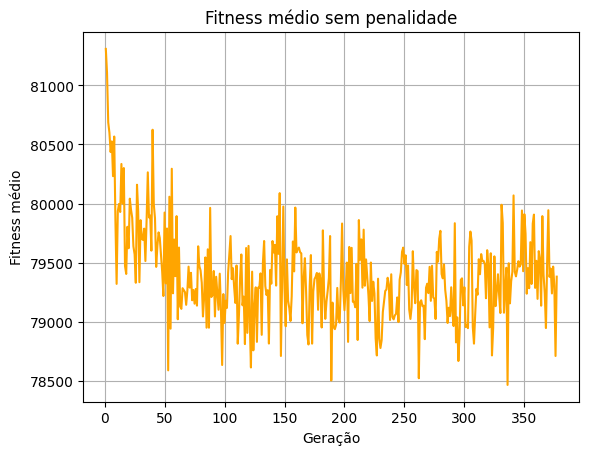

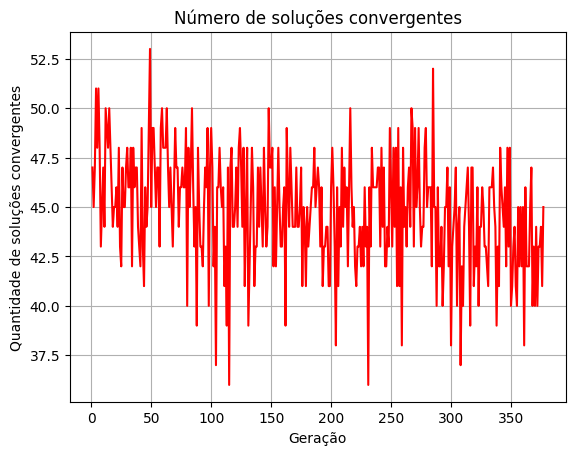

In [ ]:
import pickle 
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

NUMBER = 9

wd = os.getcwd()
caminho = Path(os.path.dirname(wd))

pasta = caminho / "PSO_mixed" / "Convergence" / f"{NUMBER}th_attempt"


with open(os.path.join(pasta, "medias_pso.pkl"), "rb") as f:
    medias = pickle.load(f)

with open(os.path.join(pasta, "fitness_pso.pkl"), "rb") as f:
    fitness = pickle.load(f)

with open(os.path.join(pasta, "medias_converg_pso.pkl"), "rb") as f:
    medias_converg = pickle.load(f)

with open(os.path.join(pasta, "contador_converg_pso.pkl"), "rb") as f:
    contador_converg = pickle.load(f)

X = np.linspace(1, len(medias_converg), len(medias_converg))

eixo_y = (medias, fitness, medias_converg, contador_converg)
titles = ("Fitness médio por geração", "Melhor Fitness geral", "Fitness médio sem penalidade", "Número de soluções convergentes")
labels_y_axis = ("Fitness médio", "Fitness", "Fitness médio", "Quantidade de soluções convergentes")
colors = ("green", "blue", "orange", "red")

for valor, label, title, color in zip(eixo_y, labels_y_axis, titles, colors):
    plt.plot(X, valor, color=color)
    plt.xlabel("Geração")
    plt.ylabel(label)
    plt.title(title)
    plt.grid(True)
    plt.show()

Análise das Barras

In [6]:
buses_df = dss_tools.model.buses_df
solution_buses_fixed = []

for bus in solution_buses:
    solution_buses_fixed.append(bus.split(".")[0])

display(buses_df.query(f"name in {solution_buses_fixed}"))

,name,nodes,num_nodes,kv_base,distance,coord_defined,x,y,latitude,longitude,all_pce_active_bus,all_pde_active_bus,line_list,line_total_miles,load_list,section_id,total_customers
445,82034745002086,"[1, 2, 3]",3,7.967434,0.158116,1,-49.322823,-16.578937,0.0,0.0,[Storage.battery_1],"[Line.smt_53072921, Line.smt_53074017]","[LINE.smt_53072921, LINE.smt_53074017]",0.0,[None],0,0
453,81489215002086,"[1, 2, 3]",3,7.967434,2.312860,1,-49.317397,-16.592395,0.0,0.0,[Storage.battery_0],"[Line.smt_53073005, Line.smt_53073784]","[LINE.smt_53073005, LINE.smt_53073784]",0.0,[None],0,0
463,81460505002086,"[1, 2, 3]",3,7.967434,2.713882,1,-49.318835,-16.595420,0.0,0.0,[Storage.battery_3],"[Line.smt_53073013, Line.smt_53073014, Transfo...","[LINE.smt_53073013, LINE.smt_53073014]",0.0,[None],0,0
1186,82032765552819,"[1, 2, 3, 4]",4,0.219393,7.166839,1,-49.323548,-16.614623,0.0,0.0,"[Load.m2_trf_5552819a, Load.m1_trf_5552819a, R...",[Transformer.trf_5552819a],[None],0.0,"[LOAD.m2_trf_5552819a, LOAD.m1_trf_5552819a]",0,0
1201,82036275286964,"[1, 2, 3, 4]",4,0.219393,5.884288,1,-49.320532,-16.615113,0.0,0.0,"[Load.m2_trf_5286964a, Load.m1_trf_5286964a, R...",[Transformer.trf_5286964a],[None],0.0,"[LOAD.m2_trf_5286964a, LOAD.m1_trf_5286964a]",0,0


In [22]:
colors = ["red", "blue", "green", "purple", "yellow"]
bus_list = []
for i, bus in enumerate(solution_buses):
    bus_list.append(dss_tools.interactive_view.circuit_get_bus_marker(name=bus, color=colors[i], size=10)) 

#bus_list = [dss_tools.interactive_view.circuit_get_bus_marker(name=solution_buses[3], color=colors[3], size=10)]

print(bus_list)

dss_tools.interactive_view.circuit_geoplot(parameter="active power", title="Circuit Plot with Solution Buses", show=True, bus_markers=bus_list)

[CircuitBusMarker(name='82044325557353', symbol='square', size=10, color='red', marker_name='82044325557353'), CircuitBusMarker(name='82062465002086', symbol='square', size=10, color='blue', marker_name='82062465002086'), CircuitBusMarker(name='82040735002086', symbol='square', size=10, color='green', marker_name='82040735002086'), CircuitBusMarker(name='82032275002086', symbol='square', size=10, color='purple', marker_name='82032275002086'), CircuitBusMarker(name='82044385286867', symbol='square', size=10, color='yellow', marker_name='82044385286867')]


Criação do Mapa pro Slide

,name,nodes,num_nodes,kv_base,distance,coord_defined,x,y,latitude,longitude,all_pce_active_bus,all_pde_active_bus,line_list,line_total_miles,load_list,section_id,total_customers
0,84808465002086,"[1, 2, 3]",3,7.967434,0.000000,1,-49.322706,-16.577557,0.0,0.0,[Vsource.source],"[Line.smt_53951427, Line.smt_88888868971, Line...","[LINE.smt_53951427, LINE.smt_88888868971, LINE...",0.0,[None],0,0
1,81463945002086,"[1, 2, 3]",3,7.967434,4.408302,1,-49.320085,-16.605821,0.0,0.0,[None],"[Line.cmt_5281595, Line.smt_53072500]","[LINE.cmt_5281595, LINE.smt_53072500]",0.0,[None],0,0
2,81463945002086b,"[1, 2, 3]",3,7.967434,4.409302,1,-49.320085,-16.605821,0.0,0.0,[None],"[Line.cmt_5281595, Line.smt_53001146]","[LINE.cmt_5281595, LINE.smt_53001146]",0.0,[None],0,0
3,82034695002086,"[1, 2, 3]",3,7.967434,8.158531,1,-49.329454,-16.633219,0.0,0.0,[None],"[Line.cmt_5286666, Line.smt_53072619]","[LINE.cmt_5286666, LINE.smt_53072619]",0.0,[None],0,0
4,82034695002086b,"[1, 2, 3]",3,7.967434,8.159531,1,-49.329454,-16.633219,0.0,0.0,[None],"[Line.cmt_5286666, Line.smt_53072618]","[LINE.cmt_5286666, LINE.smt_53072618]",0.0,[None],0,0


<Axes: >

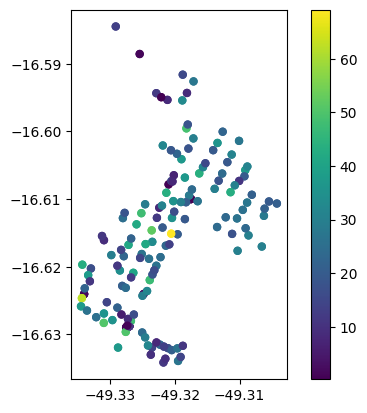

In [7]:
import geopandas as gpd
import pandas as pd

#Carregamento das cargas

loads_df = dss_tools.model.loads_df
loads_df["kw"] = pd.to_numeric(loads_df["kw"], errors="coerce")
loads_df["kv"] = pd.to_numeric(loads_df["kv"], errors="coerce")  

loads_df["kw"].describe()

display(buses_df.head())

df_loads = loads_df[["name", "kw", "kv", "bus1"]]

df_loads["bus"] = df_loads["bus1"].str.split(".").str[0]

df_loads = df_loads.merge(buses_df[["name", "x", "y"]], left_on="bus", right_on="name", how="left")

df_loads = df_loads.drop(columns=["name_y"])
df_loads = df_loads.rename(columns={"name_x": "name"})


gdf_loads = gpd.GeoDataFrame(df_loads, geometry=gpd.points_from_xy(df_loads["x"], df_loads["y"]), crs="EPSG:4674")

gdf_loads.plot(column="kw", legend=True, markersize=25)

<Axes: >

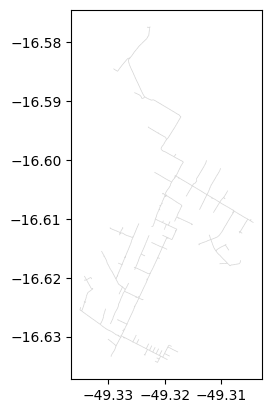

In [8]:
from shapely.geometry import LineString
import geopandas as gpd

lines_df = dss_tools.model.lines_df

lines_df.head()

df_lines = lines_df[["name", "bus1", "bus2", "length"]]

df_lines["bus_1"] = df_lines["bus1"].str.split(".").str[0]
df_lines["bus_2"] = df_lines["bus2"].str.split(".").str[0]

##### MERGE para Bus1

df_lines = df_lines.merge(buses_df[["name", "x", "y"]], left_on="bus_1", right_on="name", how="left")

df_lines = df_lines.rename(
    columns={
        "name_x": "name",
        "x": "x1",
        "y": "y1"
        })

df_lines = df_lines.drop(columns=["name_y"])

###### MERGE para Bus2

df_lines = df_lines.merge(buses_df[["name", "x", "y"]], left_on="bus_2", right_on="name", how="left")

df_lines = df_lines.rename(
    columns={
        "name_x": "name",
        "x": "x2",
        "y": "y2"
        })

df_lines = df_lines.drop(columns=["name_y"])


#Correção das linhas curtas com barras sem coordenadas x e y
df_lines.loc[df_lines["x2"] == 0, "x2"] = df_lines["x1"]
df_lines.loc[df_lines["y2"] == 0, "y2"] = df_lines["y1"]

df_lines["geometry"] = df_lines.apply(
    lambda row: LineString([
        (row["x1"], row["y1"]),
        (row["x2"], row["y2"])
    ]),
    axis=1
)


gdf_lines = gpd.GeoDataFrame(
    df_lines,
    geometry="geometry",
    crs="EPSG:4674"
)

gdf_lines.plot(
    color="lightgray",
    linewidth=0.5
)



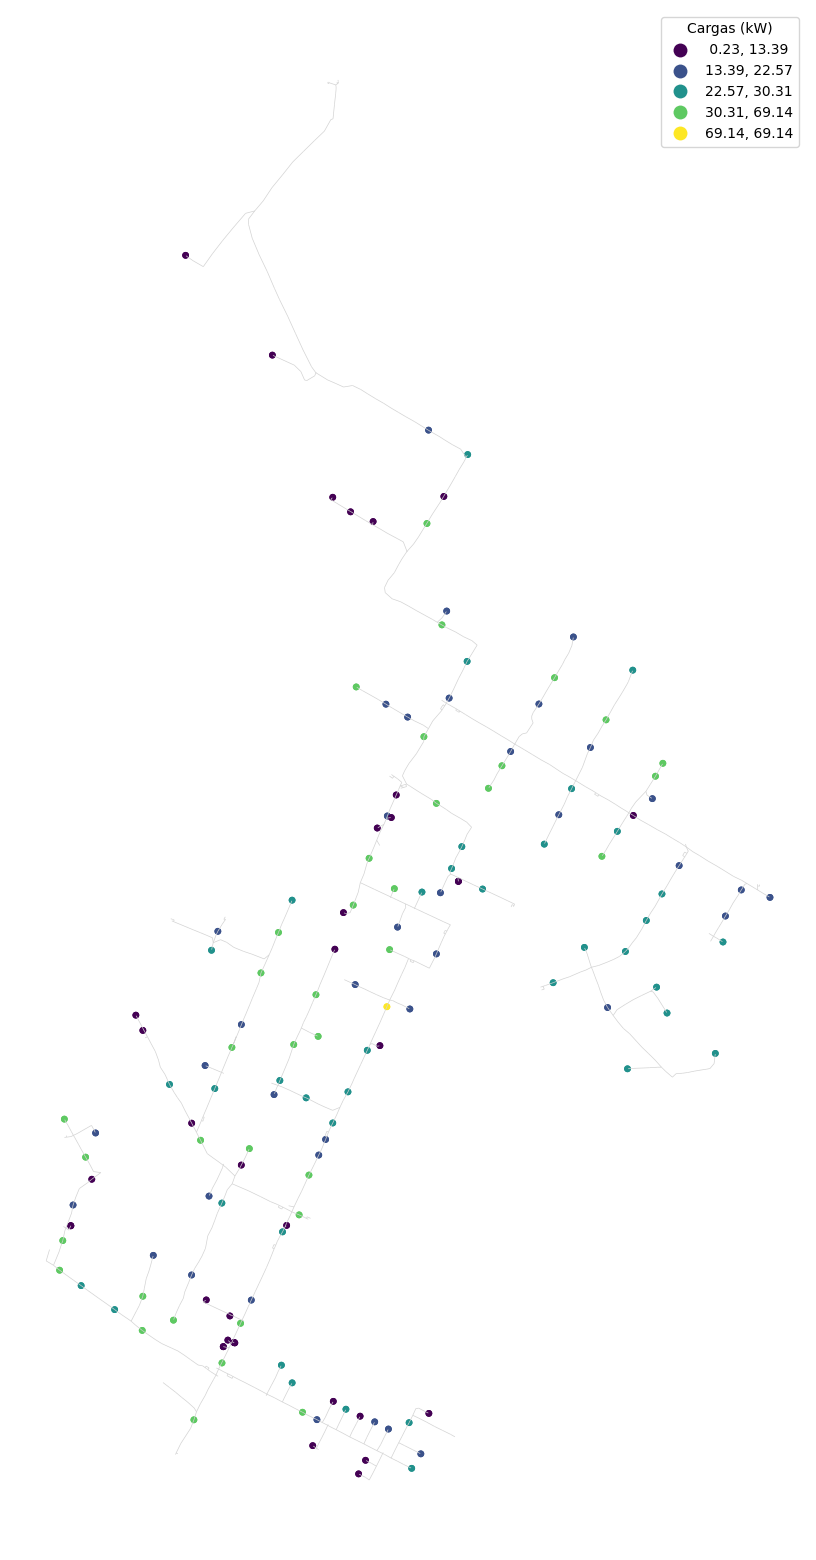

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(20, 20))

gdf_loads.plot(
    ax=ax,
    column="kw",
    scheme="userdefined",
    legend=True,
    markersize=15,
    zorder=2,
    legend_kwds=dict(title="Cargas (kW)"),
    classification_kwds={"bins": [13.39,  22.57, 30.31, 69.14]}
)

gdf_lines.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.5
)



ax.set_axis_off()
plt.show()

Mapa Completo (Contextily)

c:\Users\ivan.pereira\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


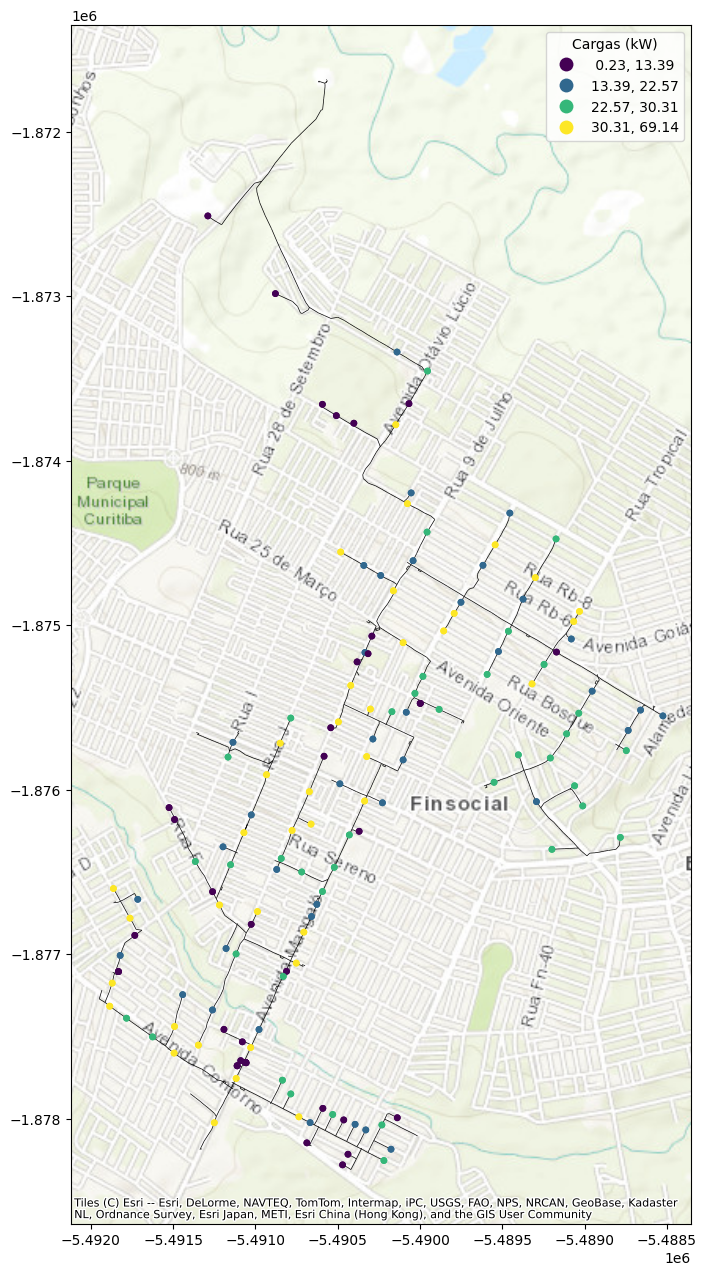

In [10]:
import matplotlib.pyplot as plt
import contextily as cx

gdf_loads_3857 = gdf_loads.to_crs(epsg=3857)
gdf_lines_3857 = gdf_lines.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(8, 16))

# Linhas da rede
gdf_lines_3857.plot(
    ax=ax,
    color="black",
    linewidth=0.5,
    zorder=2
)

# Cargas
gdf_loads_3857.plot(
    ax=ax,
    column="kw",
    scheme="userdefined",
    legend=True,
    markersize=15,
    zorder=3,
    legend_kwds={"title": "Cargas (kW)"},
    classification_kwds={
        "bins": [13.39, 22.57, 30.31]
    }
)

cx.add_basemap(
    ax,
    source=cx.providers.Esri.WorldTopoMap,
    zoom="auto"
)

#ax.set_axis_off()
#plt.savefig("map_cargas_meia_ponte.jpg", dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()


Mapa com os BESS para a Solução do PSO

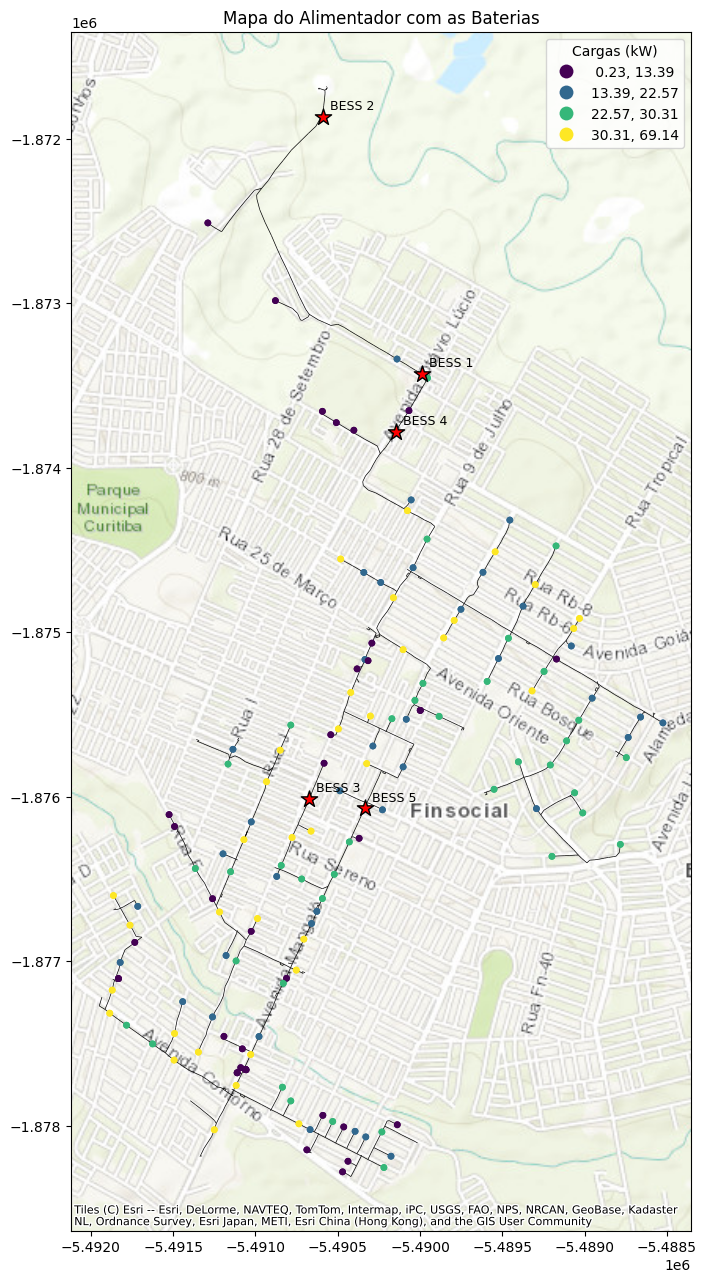

In [11]:
import matplotlib.pyplot as plt
import contextily as cx
from shapely.geometry import Point


#Criação dos pontos para as baterias
points_coords = []
names = ("BESS 1", "BESS 2", "BESS 3", "BESS 4", "BESS 5")
for bus in solution_buses_fixed:
    coord_x, coord_y = buses_df.query(f"name == '{bus}'")[["x", "y"]].iloc[0]
    points_coords.append((coord_x, coord_y))

df_points = pd.DataFrame({
    "Nome": names, 
    "Barra": solution_buses_fixed,
    "Coordenadas": points_coords
    })

df_points["geometry"] = df_points["Coordenadas"].apply(lambda x: Point(x))

gdf_points = gpd.GeoDataFrame(
    df_points, 
    geometry="geometry",
    crs="EPSG:4674"
)

gdf_loads_3857 = gdf_loads.to_crs(epsg=3857)
gdf_lines_3857 = gdf_lines.to_crs(epsg=3857)
gdf_points_3857 = gdf_points.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(8, 16))

# Linhas da rede
gdf_lines_3857.plot(
    ax=ax,
    color="black",
    linewidth=0.5,
    zorder=2
)

# Cargas
gdf_loads_3857.plot(
    ax=ax,
    column="kw",
    scheme="userdefined",
    legend=True,
    markersize=15,
    zorder=3,
    legend_kwds={"title": "Cargas (kW)"},
    classification_kwds={
        "bins": [13.39, 22.57, 30.31]
    }
)
#Pontos das baterias
gdf_points_3857.plot(
    ax=ax,
    color="red",
    marker="*",
    markersize=150,
    edgecolor="black",
    zorder=4,
    label="BESS"
)

for _, row in gdf_points_3857.iterrows():
    ax.annotate(
        row["Nome"],
        (row.geometry.x, row.geometry.y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

cx.add_basemap(
    ax,
    source=cx.providers.Esri.WorldTopoMap,
    zoom="auto"
)
plt.title("Mapa do Alimentador com as Baterias")
#ax.set_axis_off()
#plt.savefig("map_cargas_meia_ponte_baterias.jpg", dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()


Análise do SOC (Bateria)

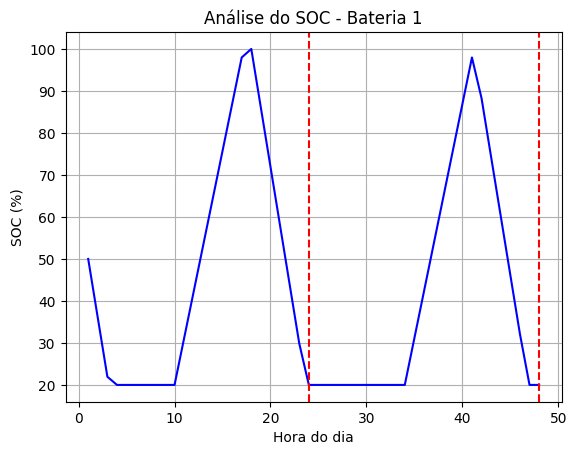

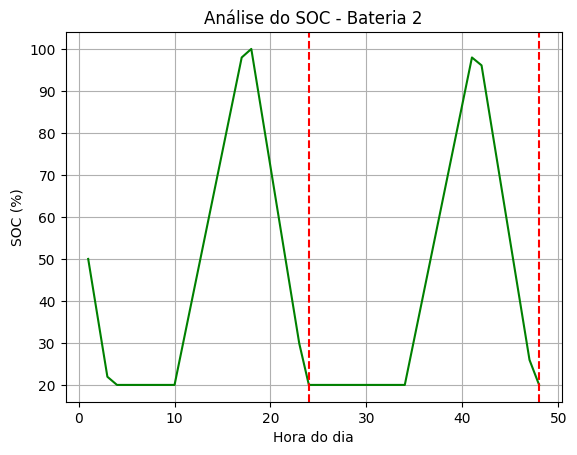

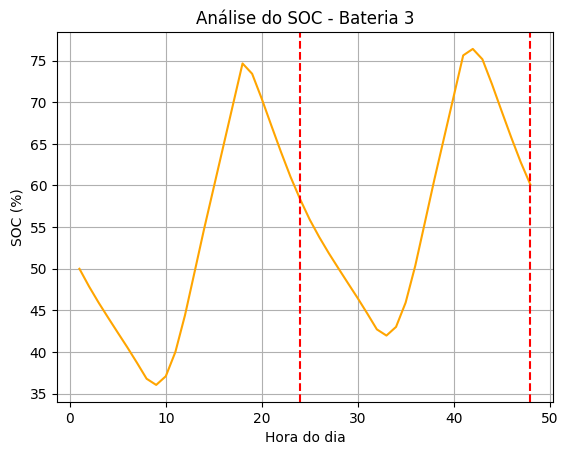

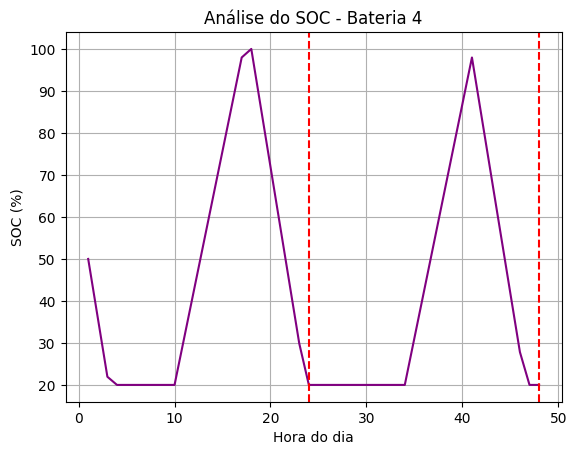

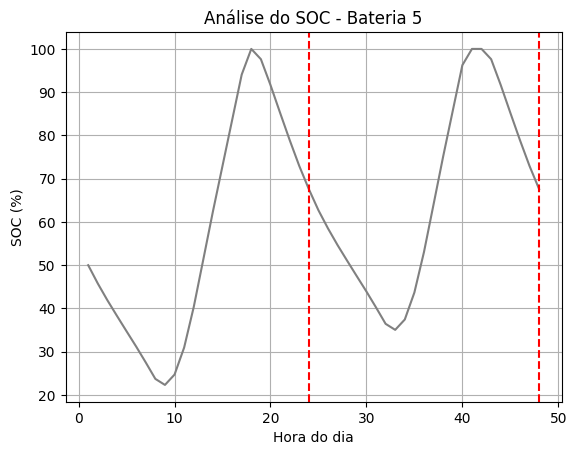

In [12]:
import matplotlib.pyplot as plt

dfs_battery = {}

for name in dss.monitors.names:
    if "battery" in name:
        dfs_battery[name] = dss_tools.results.monitor(name)

i = 0
colors = ["blue", "green", "orange", "purple", "gray"]
for name, df in dfs_battery.items():
    plt.plot(df["Hour"], df[" %kW Stored"], colors[i])
    plt.title(f"Análise do SOC - Bateria {i+1}")
    plt.xlabel("Hora do dia")
    plt.ylabel("SOC (%)")
    plt.axvline(x=24, color='red', linestyle='--', linewidth=1.5, label="24h")
    plt.axvline(x=48, color='red', linestyle='--', linewidth=1.5, label="48h")
    plt.grid(True)
    plt.show()
    i += 1

